In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/quickbite_customers.csv')

# Task 0:Setup and First Look

In [ ]:
df_original=df.copy()

In [ ]:
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [ ]:
#Converting signup_date to datetime
df['signup_date']=pd.to_datetime(df['signup_date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   gender                  1894 non-null   object        
 5   device_type             2000 non-null   object        
 6   acquisition_channel     2000 non-null   object        
 7   age                     1861 non-null   float64       
 8   tenure_months           2000 non-null   float64       
 9   app_sessions_per_month  2000 non-null   int64         
 10  delivery_time_min       1920 non-null   float64       
 11  avg_order_value         1892 non-null   float64       
 12  customer_rating         1742 non-null   float64 

In [ ]:
df.shape

(2000, 18)

Insights: We have 2000 entries

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   gender                  1894 non-null   object        
 5   device_type             2000 non-null   object        
 6   acquisition_channel     2000 non-null   object        
 7   age                     1861 non-null   float64       
 8   tenure_months           2000 non-null   float64       
 9   app_sessions_per_month  2000 non-null   int64         
 10  delivery_time_min       1920 non-null   float64       
 11  avg_order_value         1892 non-null   float64       
 12  customer_rating         1742 non-null   float64 

There are 6 columns with null values.

In [ ]:
df.describe()

,signup_date,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
count,2000,2000.000000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000.00000,2000.000000
mean,2024-05-28 18:57:35.999999744,1.600500,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,34.89650,12995.852000
min,2023-01-01 00:00:00,1.000000,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,5.00000,523.000000
25%,2023-09-18 18:00:00,1.000000,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,17.00000,4085.750000
50%,2024-05-29 12:00:00,1.000000,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,24.00000,7142.000000
75%,2025-02-15 06:00:00,2.000000,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,32.00000,12781.250000
max,2025-11-05 00:00:00,3.000000,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,400.00000,855443.000000
std,NaN,0.772138,7.619334,9.981302,3.77856,19.486015,1133.673898,0.609572,9.483931,18.983606,49.27424,30336.382856


Insights: We can see probablity of some outliers in few of the columns like age, app_sessions_per_month,delivery_time_min,	avg_order_value, days_since_last_order, orders_last_12m and	annual_spend.


In [ ]:
#Reporting number of missing values per column
df.isna().sum()

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,106
device_type,0
acquisition_channel,0
age,139
tenure_months,0
app_sessions_per_month,0


In [ ]:
#Their null percentages
nper=df.isna().sum()/df.isna().count() *100
nper

,0
customer_id,0.00
signup_date,0.00
city,0.00
city_tier,0.00
gender,5.30
device_type,0.00
acquisition_channel,0.00
age,6.95
tenure_months,0.00
app_sessions_per_month,0.00


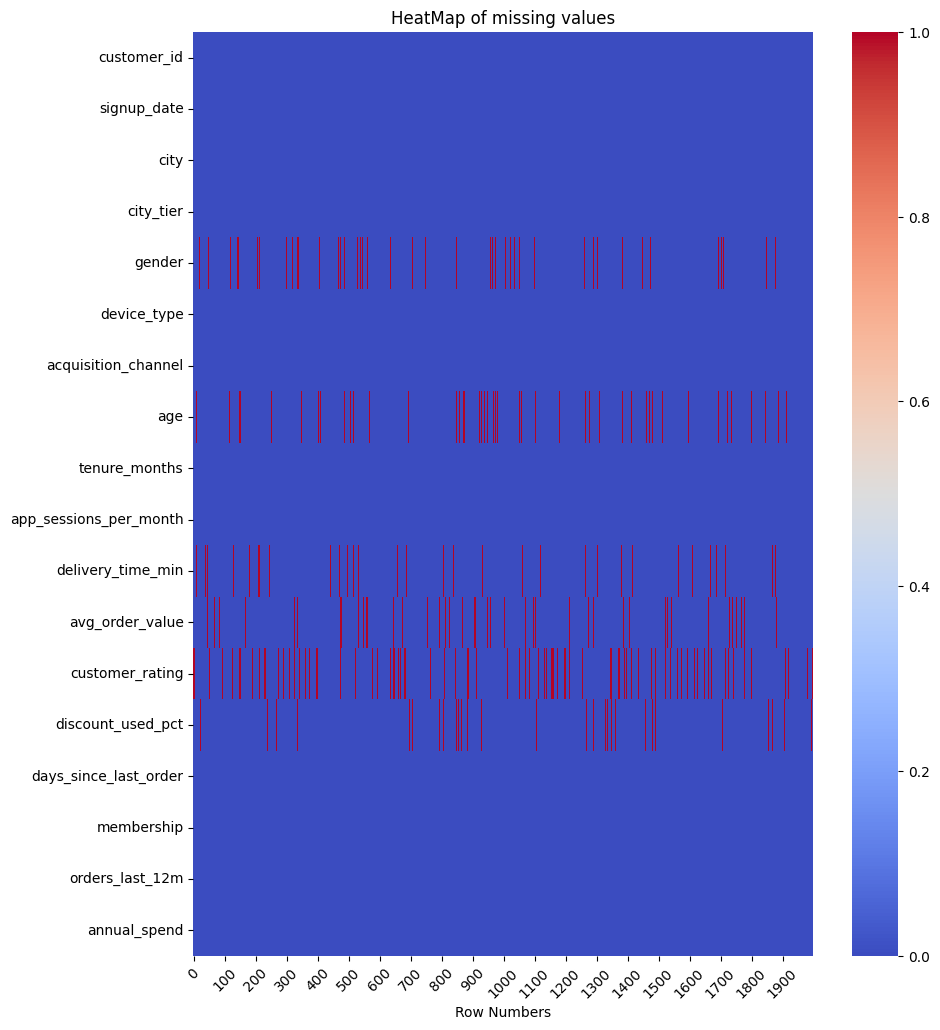

In [ ]:
plt.figure(figsize=(10,12))
sns.heatmap(df.isna().T, cmap='coolwarm',xticklabels=100)
plt.title('HeatMap of missing values')
plt.xlabel('Row Numbers')
plt.xticks(rotation=45)
plt.show()

# Task 2: Outlier Detection and Removal

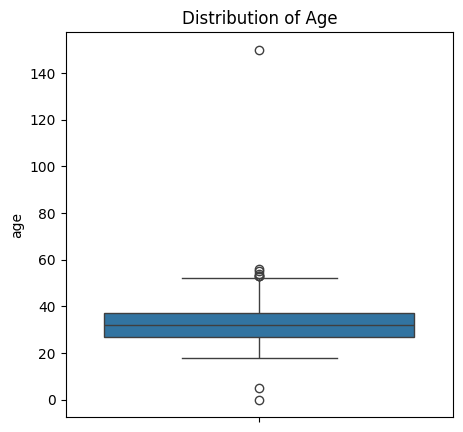

In [ ]:
#Box plot for age
plt.figure(figsize=(5,5))
sns.boxplot(y=df['age'])
plt.title('Distribution of Age')
plt.show()

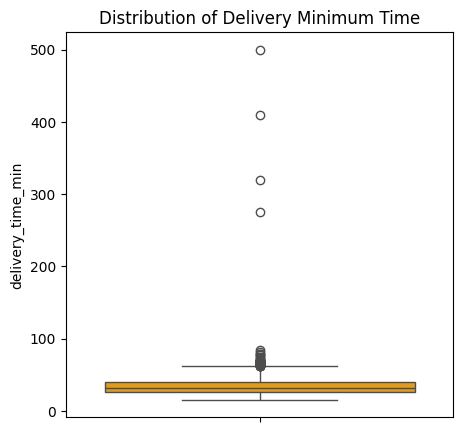

In [ ]:
#Box plot for delivery_time_min
plt.figure(figsize=(5,5))
sns.boxplot(y=df['delivery_time_min'],color='orange')
plt.title('Distribution of Delivery Minimum Time')
plt.show()

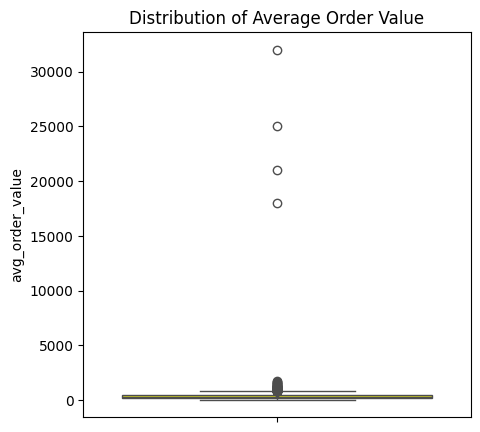

In [ ]:
#Box plot for avg_order_val
plt.figure(figsize=(5,5))
sns.boxplot(y=df['avg_order_value'],color='Yellow')
plt.title('Distribution of Average Order Value')
plt.show()

Observations: Here we can see that there are outliers in columns 'Age', 'deliver_time_min' and 'avg_order_value'

We need to find the outliers and remove them.

In [ ]:
#First we will use IQR Method
#Removing outliers from the above columns
#Q1=np.percentile(df['age'],25) -> not working because Columns has null values
cols=['age','delivery_time_min','avg_order_value']
for col in cols:
  Q1=df[col].quantile(0.25)
  Q3=df[col].quantile(0.75)
  IQR= Q3-Q1
  upper=Q3+1.5*IQR
  lower=Q1-1.5*IQR
  df_iqr=df[(df[col] >= lower) & (df[col] <= upper)]

df_iqr

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,QB101995,2023-08-07,Jaipur,2,Male,iOS,Influencer,18.0,39.4,9,42.7,254.0,3.7,36.2,6.0,Basic,13,2704.0
1996,QB101996,2025-06-07,Delhi,1,Male,iOS,Search Ads,29.0,17.0,7,20.7,249.0,4.5,24.1,6.0,Basic,17,3723.0
1997,QB101997,2025-10-15,Bengaluru,1,Male,Android,Paid Social,45.0,12.7,18,38.0,528.0,NaN,2.9,1.0,Silver,24,13736.0
1998,QB101998,2025-02-22,Indore,3,Male,iOS,Influencer,NaN,20.5,21,68.8,314.0,4.3,29.4,8.0,Platinum,37,14368.0


In [ ]:
#Removing outliers using Z-score method
cols=['age','delivery_time_min','avg_order_value']
for col in cols:
  z=(df[col]-df[col].mean())/df[col].std()
  df_z=df[z.abs() <=3]
df_z


,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,QB101995,2023-08-07,Jaipur,2,Male,iOS,Influencer,18.0,39.4,9,42.7,254.0,3.7,36.2,6.0,Basic,13,2704.0
1996,QB101996,2025-06-07,Delhi,1,Male,iOS,Search Ads,29.0,17.0,7,20.7,249.0,4.5,24.1,6.0,Basic,17,3723.0
1997,QB101997,2025-10-15,Bengaluru,1,Male,Android,Paid Social,45.0,12.7,18,38.0,528.0,NaN,2.9,1.0,Silver,24,13736.0
1998,QB101998,2025-02-22,Indore,3,Male,iOS,Influencer,NaN,20.5,21,68.8,314.0,4.3,29.4,8.0,Platinum,37,14368.0


Observation: Here we can see that IQR eliminates more outliers than Z-score method. Since the data isn't free from null values and the columns have alot of outliers it will not be a normal distribution. Hence IQR menthod is mainly prefered.






In [ ]:
# For Age Removing and contemplating the outliers
Q1=df['age'].quantile(0.25)
Q3=df['age'].quantile(0.75)
IQR= Q3-Q1
upper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR
df_age=df[(df['age'] >= lower_bound) & (df['age'] <= upper_bound)]
outliers_age=df[(df['age'] < lower_bound) | (df['age'] > upper_bound)]
outliers_age['age'].sort_values(ascending=False)


,age
1617,150.0
257,56.0
459,55.0
1843,54.0
1035,53.0
1308,53.0
572,53.0
245,5.0
1792,0.0


Insights: For age we need to cap extreme values with as 0 and 150 are not possible. Instead of deleting the records we can change the values to 0 or NA

In [ ]:
df['age']=df['age'].clip(lower=0, upper=56)
df['age'].sort_values(ascending=False)


,age
257,56.0
1617,56.0
459,55.0
1843,54.0
1308,53.0
...,...
1931,NaN
1960,NaN
1966,NaN
1991,NaN


In [ ]:
#For delivery_time Removing and contemplating the outliers
Q1=df['delivery_time_min'].quantile(0.25)
Q3=df['delivery_time_min'].quantile(0.75)
IQR= Q3-Q1
upper=Q3+1.5*IQR
lower=Q1-1.5*IQR
df_dtime=df[(df['delivery_time_min'] >= lower) & (df['delivery_time_min'] <= upper)]
outliers_delivery=df[(df['delivery_time_min'] < lower) | (df['delivery_time_min'] > upper)]
outliers_delivery['delivery_time_min'].sort_values(ascending=False)

,delivery_time_min
1417,500.0
1210,410.0
1293,320.0
1223,275.0
1616,83.9
1090,80.9
48,79.1
799,79.0
222,77.8
1925,75.3


Insights: For delivery time I think we should keep all the records because we can't ignore such high delivery time. Needs further investigation.

In [ ]:
#For Average order value Removing and contemplating the outliers
Q1=df['avg_order_value'].quantile(0.25)
Q3=df['avg_order_value'].quantile(0.75)
IQR= Q3-Q1
upper=Q3+1.5*IQR
lower=Q1-1.5*IQR
df_aov=df[(df['avg_order_value'] >= lower) & (df['avg_order_value'] <= upper)]
outliers_order=df[(df['avg_order_value'] < lower) | (df['avg_order_value'] > upper)]
outliers_order.sort_values('avg_order_value',ascending=False)

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
567,QB100567,2025-01-01,Mumbai,1,Male,Android,Referral,23.0,22.3,18,29.8,32000.0,4.9,25.5,10.0,Gold,17,5061.0
693,QB100693,2025-06-16,Bengaluru,1,Female,iOS,Organic,33.0,16.7,15,27.5,25000.0,4.2,NaN,46.0,Basic,17,7519.0
1782,QB101782,2025-07-08,Delhi,1,Female,iOS,Influencer,29.0,16.0,10,33.4,21000.0,NaN,11.4,15.0,Basic,7,826.0
156,QB100156,2025-01-05,Delhi,1,Male,Android,Search Ads,18.0,22.1,10,38.1,18000.0,NaN,23.6,0.0,Basic,17,4964.0
1658,QB101658,2024-06-26,Bengaluru,1,Female,iOS,Referral,37.0,28.6,15,29.0,1729.0,4.9,21.4,2.0,Basic,37,57128.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1565,QB101565,2024-10-25,Hyderabad,1,Female,iOS,Paid Social,30.0,24.5,19,NaN,831.0,3.3,11.6,59.0,Platinum,20,22702.0
279,QB100279,2025-05-28,Indore,3,Male,iOS,Referral,26.0,17.4,16,30.0,827.0,4.8,16.2,12.0,Basic,13,9880.0
1578,QB101578,2024-04-17,Kochi,3,Male,Web,Referral,43.0,30.9,12,33.2,827.0,5.0,2.7,56.0,Basic,13,10606.0
1731,QB101731,2023-05-09,Mumbai,1,Female,Android,Paid Social,41.0,42.4,11,19.3,825.0,4.1,16.7,20.0,Basic,77,58220.0


Insights: We should keep the outliers as avg order value column is influencial. And such high avg spend is worth investigating.

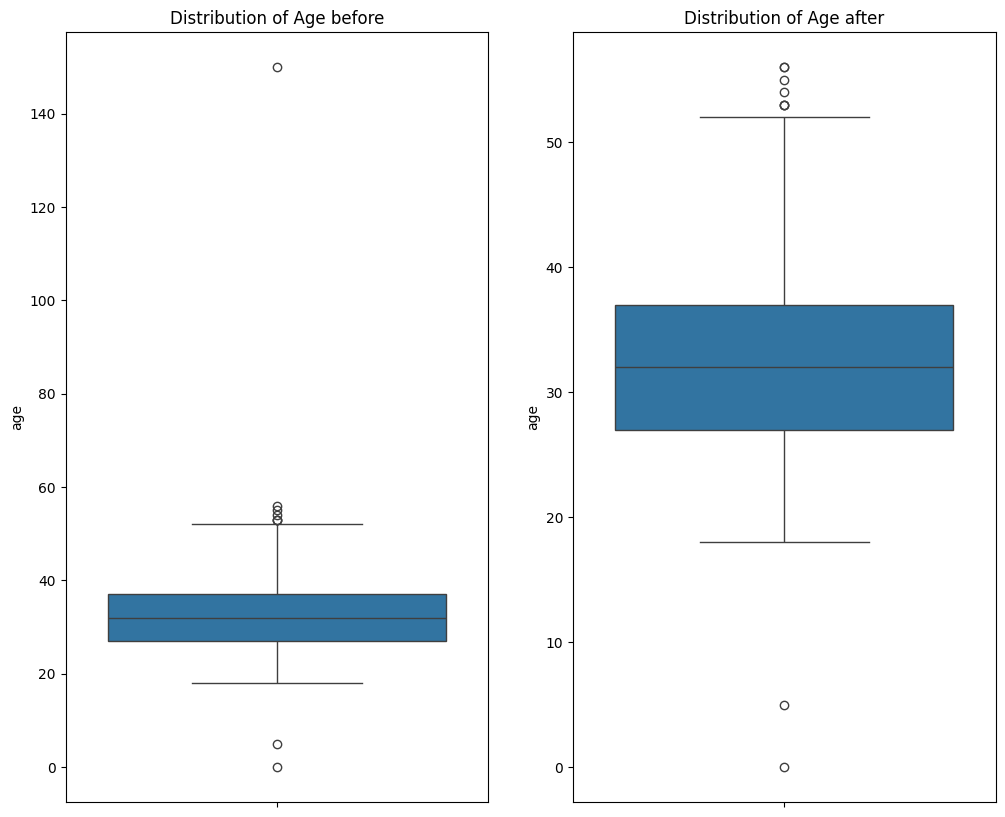

In [ ]:
#For age caping the extreme value
fig,axes=plt.subplots(1,2,figsize=(12,10))
sns.boxplot(y=df_original['age'], ax=axes[0])
axes[0].set_title('Distribution of Age before')
sns.boxplot(y=df['age'], ax=axes[1])
axes[1].set_title('Distribution of Age after')
plt.show()

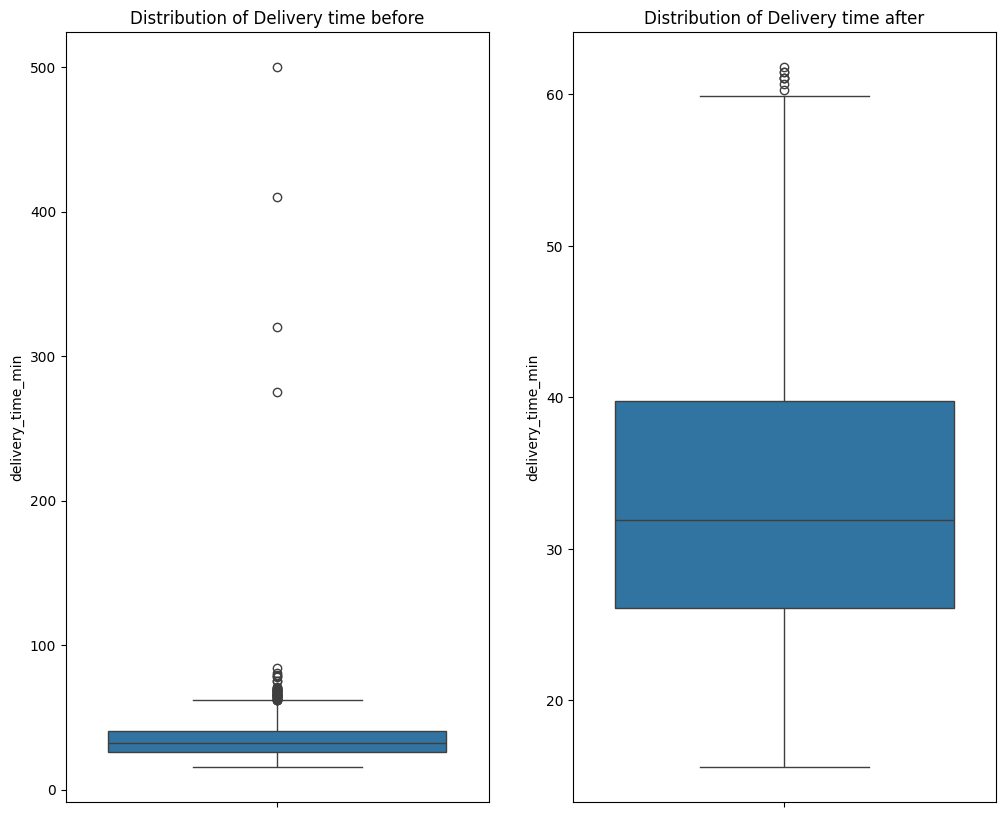

In [ ]:
#For delivery time decided to keep the outliers for further investigation but after plot shows plot without outliers.
fig,axes=plt.subplots(1,2,figsize=(12,10))
sns.boxplot(y=df['delivery_time_min'], ax=axes[0])
axes[0].set_title('Distribution of Delivery time before')
sns.boxplot(y=df_dtime['delivery_time_min'], ax=axes[1])
axes[1].set_title('Distribution of Delivery time after')
plt.show()

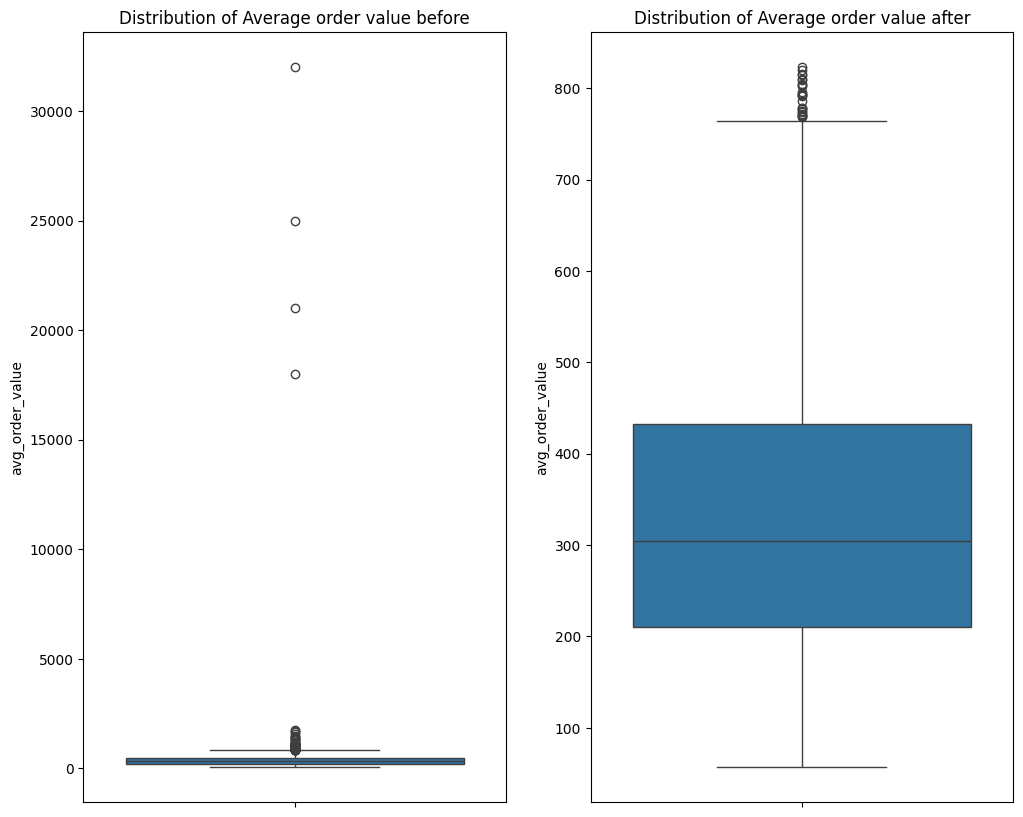

In [ ]:
#For avg order value decided to keep the outliers for further investigation but after plot shows plot without outliers.
fig,axes=plt.subplots(1,2,figsize=(12,10))
sns.boxplot(y=df['avg_order_value'], ax=axes[0])
axes[0].set_title('Distribution of Average order value before')
sns.boxplot(y=df_aov['avg_order_value'], ax=axes[1])
axes[1].set_title('Distribution of Average order value after')
plt.show()

### After treating outliers for only **AGE** and keeping the outliers for **delivery time** and **Average spend** for futrther investigation

# Task 1: Missing Value Imputations

In [ ]:
df_imp=df.copy()

In [ ]:
# before imputing age
df['age'].isna().sum()

np.int64(139)

In [ ]:
#AfterImputing null values for age column and filling them with median

df_imp['age']=df_imp['age'].fillna(df_imp['age'].median())
df_imp['age'].isna().sum()
#Filled with median and not mean as median is not affected by the outliers, even if the outliers aren't handled or removed.
#filling null values with median will not distort my distribution

np.int64(0)

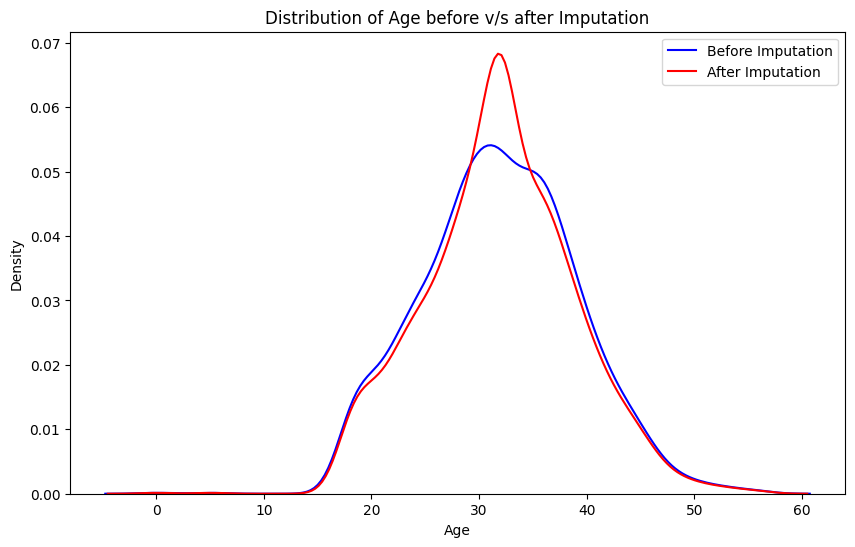

In [152]:
#Plot KDE
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df,x='age', color='blue',label='Before Imputation')
sns.kdeplot(data=df_imp,x='age', color='red',label='After Imputation')
plt.legend()
plt.title('Distribution of Age before v/s after Imputation')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

In [ ]:
#Before imputing Delivery Time
df['delivery_time_min'].isna().sum()

np.int64(80)

In [ ]:
#After Imputing null values for age column and filling them with median
df_imp['delivery_time_min']=df_imp['delivery_time_min'].fillna(df_imp['delivery_time_min'].median())
df_imp['delivery_time_min'].isna().sum()
# Imputing the null values with mean would have distorted the right-skewed distribution

np.int64(0)

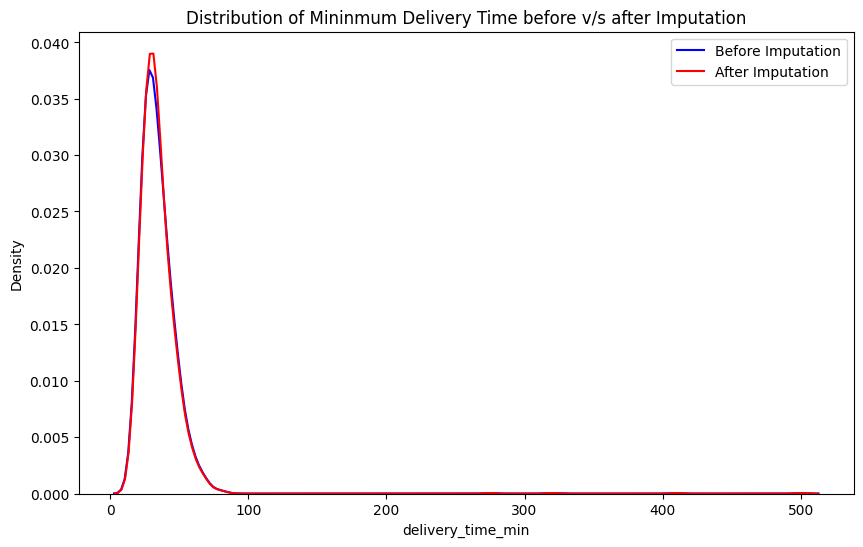

In [153]:
#KDE Plot
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df,x='delivery_time_min', color='blue',label='Before Imputation')
sns.kdeplot(data=df_imp,x='delivery_time_min', color='red',label='After Imputation')
plt.legend()
plt.title('Distribution of Mininmum Delivery Time before v/s after Imputation')
plt.xlabel('delivery_time_min')
plt.ylabel('Density')
plt.show()

In [ ]:
#Before imputing Average order value
df['avg_order_value'].isna().sum()

np.int64(108)

In [ ]:
#Imputing Average order value with group by median
#global fill
df_imp['avg_order_value_global_fill']=df_imp['avg_order_value'].fillna(df_imp['avg_order_value'].median())

#group wise fill

df_imp['avg_order_value_group']=df_imp['avg_order_value'].fillna(df_imp.groupby('city_tier')['avg_order_value'].transform('median'))

df_imp[['avg_order_value_group','avg_order_value_global_fill']]

,avg_order_value_group,avg_order_value_global_fill
0,572.0,572.0
1,329.0,329.0
2,118.0,118.0
3,303.0,303.0
4,191.0,191.0
...,...,...
1995,254.0,254.0
1996,249.0,249.0
1997,528.0,528.0
1998,314.0,314.0


In [ ]:
df_imp[['avg_order_value_group','avg_order_value_global_fill']].isna().sum()


,0
avg_order_value_group,0
avg_order_value_global_fill,0


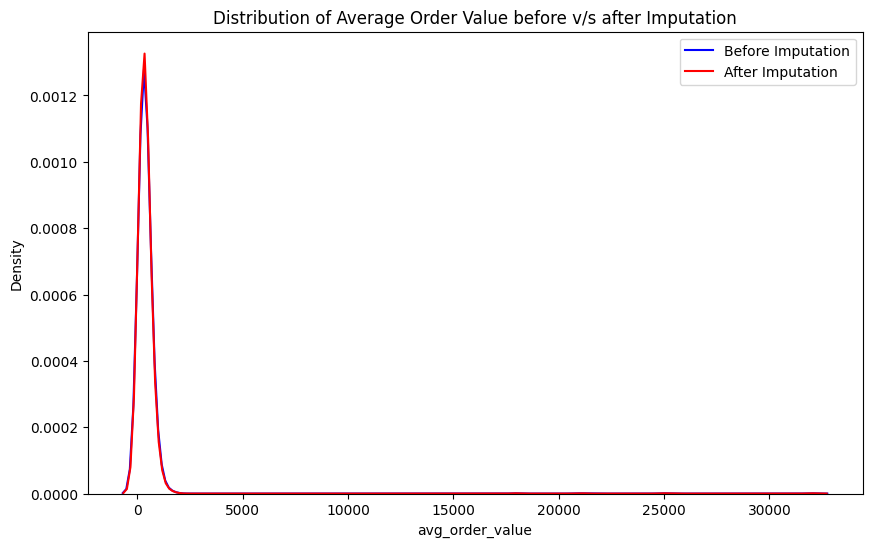

In [154]:
#KDE Plot
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df,x='avg_order_value', color='blue',label='Before Imputation')
sns.kdeplot(data=df_imp,x='avg_order_value_group', color='red',label='After Imputation')
plt.legend()
plt.title('Distribution of Average Order Value before v/s after Imputation')
plt.xlabel('avg_order_value')
plt.ylabel('Density')
plt.show()

In [ ]:
#Before imputing Customer rating
df['customer_rating'].isna().sum()


np.int64(258)

In [ ]:
#After Imputing null values for customer_ratings
#global fill -> Prefered
df_imp['customer_rating_global']=df_imp['customer_rating'].fillna(df_imp['customer_rating'].median())

#group fill
df_imp['customer_rating_group']=df_imp['customer_rating'].fillna(df_imp.groupby('city_tier')['customer_rating'].transform('median'))

df_imp[['customer_rating_global','customer_rating_group']].isna().sum()



,0
customer_rating_global,0
customer_rating_group,0


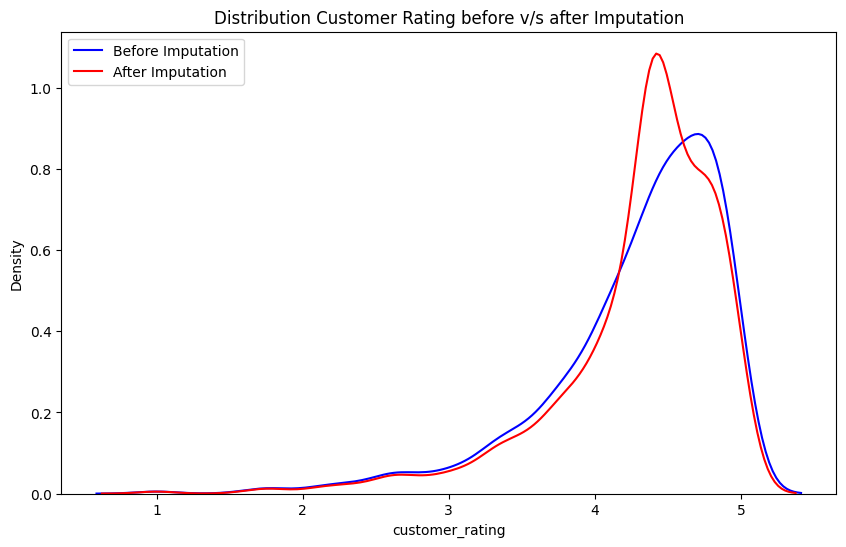

In [155]:
#KDE Plot
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df,x='customer_rating', color='blue',label='Before Imputation')
sns.kdeplot(data=df_imp,x='customer_rating_global', color='red',label='After Imputation')
plt.legend()
plt.title('Distribution Customer Rating before v/s after Imputation')
plt.xlabel('customer_rating')
plt.ylabel('Density')
plt.show()

In [ ]:
#Lets check if missing null values is related to long delivery time
df.sort_values(['delivery_time_min','customer_rating'],ascending=[False,False])

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
1417,QB101417,2023-06-27,Hyderabad,1,Male,Android,Search Ads,43.0,40.7,19,500.0,273.0,5.0,13.3,4.0,Platinum,20,7390.0
1210,QB101210,2023-04-16,Jaipur,2,Female,Android,Paid Social,33.0,43.1,14,410.0,294.0,4.8,15.7,15.0,Basic,17,4605.0
1293,QB101293,2025-01-28,Bengaluru,1,Female,Web,Organic,33.0,21.4,12,320.0,169.0,4.8,21.7,1.0,Basic,24,3616.0
1223,QB101223,2025-05-02,Pune,2,Male,Android,Influencer,37.0,18.2,10,275.0,178.0,4.5,30.4,27.0,Basic,20,3020.0
1616,QB101616,2025-04-09,Mumbai,1,Male,Android,Referral,41.0,19.0,22,83.9,322.0,NaN,19.3,112.0,Gold,24,8728.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
731,QB100731,2024-12-13,Mumbai,1,NaN,iOS,Paid Social,29.0,22.9,9,NaN,548.0,NaN,19.7,72.0,Basic,17,8398.0
960,QB100960,2024-02-01,Hyderabad,1,Male,Android,Organic,30.0,33.4,7,NaN,727.0,NaN,41.9,12.0,Basic,94,54021.0
1399,QB101399,2025-06-24,Bengaluru,1,Female,iOS,Search Ads,32.0,16.5,20,NaN,423.0,NaN,24.7,7.0,Gold,20,9270.0
1517,QB101517,2024-12-02,Kochi,3,Male,iOS,Organic,29.0,23.3,19,NaN,224.0,NaN,22.4,15.0,Platinum,28,8075.0


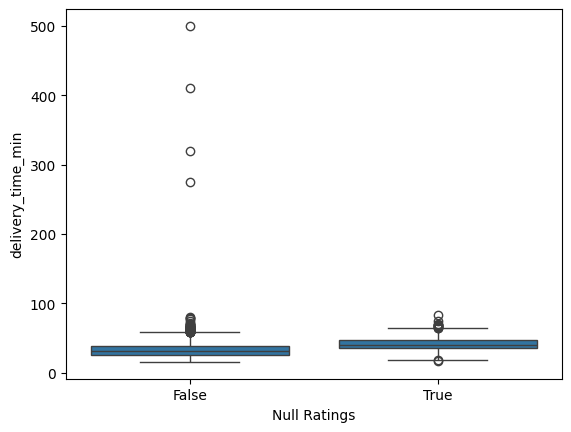

In [ ]:
#Plotting box plot to check if the null results in customer rating is actually due to delivery time
sns.boxplot(data=df, x=df['customer_rating'].isna(), y='delivery_time_min')
plt.xlabel('Null Ratings')
plt.show()

Insight:
According to the boxplot above, the result of null values slightly relate to the delivery time showing that with slow delivery people tend to not give any customer rating.

In [ ]:
#Before Imputing discount_used_pct
df['discount_used_pct'].isna().sum()

np.int64(104)

In [ ]:
#After Imputing discount_used_pct
#with mean

df_imp['discount_used_pct_mean']=df_imp['discount_used_pct'].fillna(df_imp['discount_used_pct'].mean())

#with median

df_imp['discount_used_pct_median']=df_imp['discount_used_pct'].fillna(df_imp['discount_used_pct'].median())

df_imp[['discount_used_pct_mean','discount_used_pct_median']]


,discount_used_pct_mean,discount_used_pct_median
0,21.6,21.6
1,0.0,0.0
2,17.8,17.8
3,42.9,42.9
4,29.2,29.2
...,...,...
1995,36.2,36.2
1996,24.1,24.1
1997,2.9,2.9
1998,29.4,29.4


In [ ]:
df_imp[['discount_used_pct_mean','discount_used_pct_median']].isna().sum()

,0
discount_used_pct_mean,0
discount_used_pct_median,0


Insights:
Both values appears to be same. It can be double checked by looking at the values of '50%' and 'mean' of df.describe()

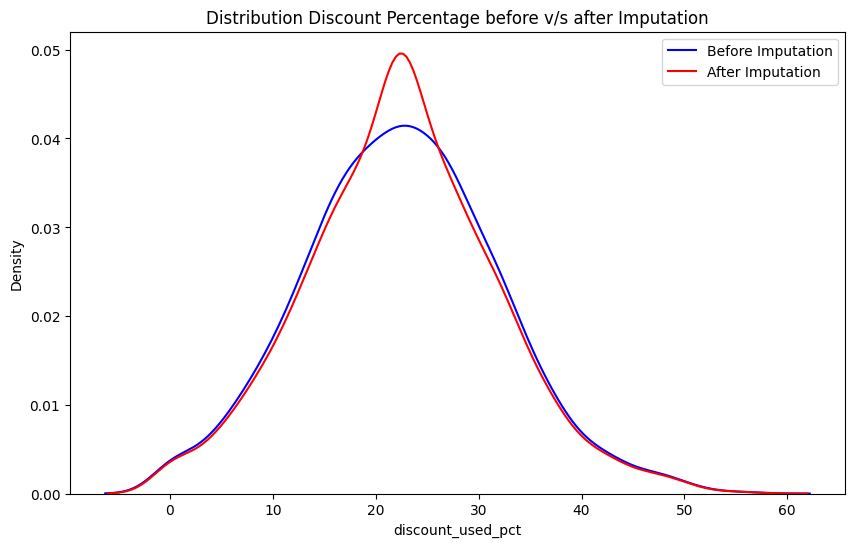

In [156]:
#KDE Plot
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df,x='discount_used_pct', color='blue',label='Before Imputation')
sns.kdeplot(data=df_imp,x='discount_used_pct_median', color='red',label='After Imputation')
plt.legend()
plt.title('Distribution Discount Percentage before v/s after Imputation')
plt.xlabel('discount_used_pct')
plt.ylabel('Density')
plt.show()

In [ ]:
#Before imputation of gender
df['gender'].isna().sum()


np.int64(106)

In [ ]:
#After Imputation
#with mode
df_imp['gender_mode']=df_imp['gender'].fillna(df_imp['gender'].mode()[0])

#with 'Unknown' catergory
df_imp['gender_clean']=df_imp['gender'].fillna('Unknown')
df_imp[['gender_mode','gender_clean']].isna().sum()

,0
gender_mode,0
gender_clean,0


Insights: I believe creating another category as 'Unknown' will be more honest as mode of the gender can can give us a wrong data about percentage of male, female or others, which can lead to wrongful insights.

KDE plot will not be possible as gender is a catergorical column

# Task 3: Distribution Shapes with KDE Plots

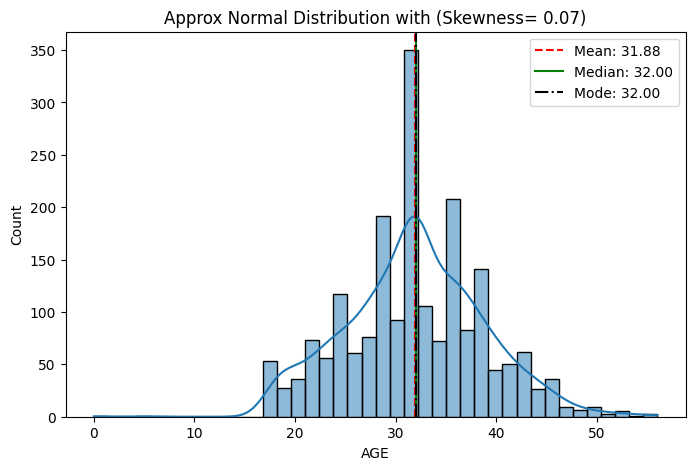

In [ ]:
#AGE
skew_val=df_imp['age'].skew()
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df_imp , x='age',  kde=True, ax=ax)
ax.axvline(df_imp['age'].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {df_imp['age'].mean():.2f}')
ax.axvline(df_imp['age'].median(), color='Green', linestyle='-', linewidth=1.5, label=f'Median: {df_imp['age'].median():.2f}')
ax.axvline(df_imp['age'].mode()[0], linestyle='-.', color='black',linewidth=1.5, label= f'Mode: {df_imp['age'].mode()[0]:.2f}')
plt.xlabel('AGE')
ax.legend()
plt.title(f"Approx Normal Distribution with (Skewness= {skew_val:.2f})")
plt.show()



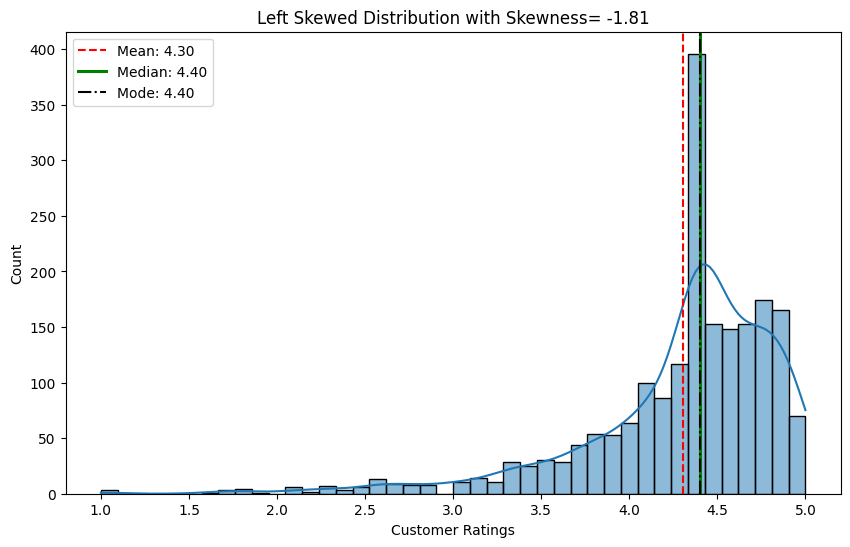

In [ ]:

#Customer Rating
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df_imp , x='customer_rating_global',  kde=True, ax=ax)
ax.axvline(df_imp['customer_rating_global'].mean(), linestyle='--', color='red',linewidth=1.5, label= f'Mean: {df_imp['customer_rating_global'].mean():.2f}')
ax.axvline(df_imp['customer_rating_global'].median(), linestyle='-', color='green',linewidth=2.2, label= f'Median: {df_imp['customer_rating_global'].median():.2f}')
ax.axvline(df_imp['customer_rating_global'].mode()[0], linestyle='-.', color='black',linewidth=1.5, label= f'Mode: {df_imp['customer_rating_global'].mode()[0]:.2f}')
ax.legend()
plt.xlabel('Customer Ratings')
plt.title(f'Left Skewed Distribution with Skewness= {df_imp['customer_rating_global'].skew() :.2f}')
plt.show()

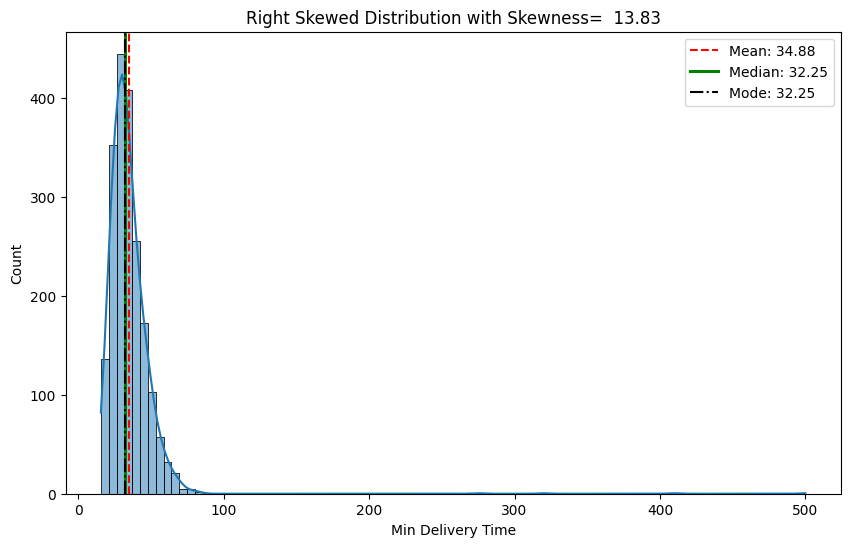

In [ ]:
#delivery_time_min
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df_imp , x='delivery_time_min',  kde=True, ax=ax)
ax.axvline(df_imp['delivery_time_min'].mean(), linestyle='--', color='red',linewidth=1.5, label= f'Mean: {df_imp['delivery_time_min'].mean():.2f}')
ax.axvline(df_imp['delivery_time_min'].median(), linestyle='-', color='green',linewidth=2.2, label= f'Median: {df_imp['delivery_time_min'].median():.2f}')
ax.axvline(df_imp['delivery_time_min'].mode()[0], linestyle='-.', color='black',linewidth=1.5, label= f'Mode: {df_imp['delivery_time_min'].mode()[0]:.2f}')

ax.legend()
plt.xlabel('Min Delivery Time')
plt.title(f'Right Skewed Distribution with Skewness= {df_imp['delivery_time_min'].skew(): .2f}')
plt.show()

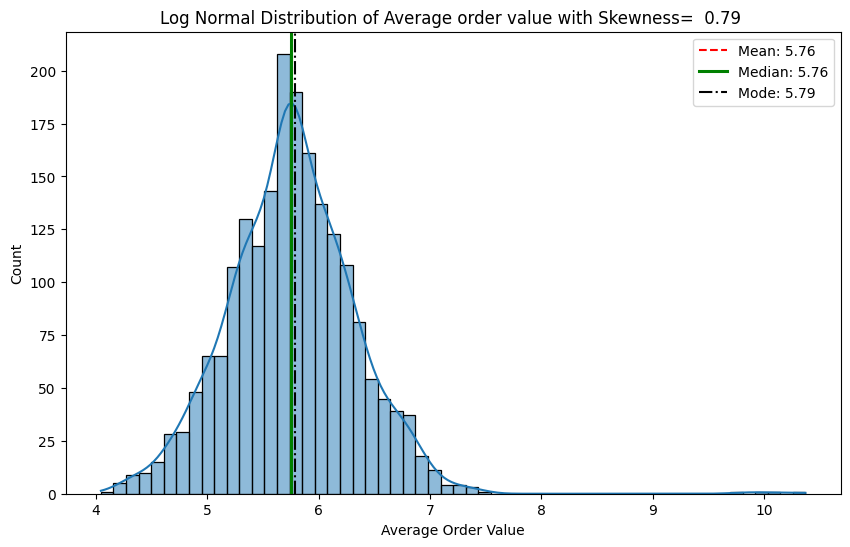

In [ ]:
#avg_order_value
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(x=np.log(df_imp['avg_order_value_group']),  kde=True, ax=ax)
ax.axvline(np.log(df_imp['avg_order_value_group']).mean(), linestyle='--', color='red',linewidth=1.5, label= f'Mean: {np.log(df_imp['avg_order_value_group']).mean():.2f}')
ax.axvline(np.log(df_imp['avg_order_value_group']).median(), linestyle='-', color='green',linewidth=2.2, label= f'Median: {np.log(df_imp['avg_order_value_group']).median():.2f}')
ax.axvline(np.log(df_imp['avg_order_value_group']).mode()[0], linestyle='-.', color='black',linewidth=1.5, label= f'Mode: {np.log(df_imp['avg_order_value_group']).mode()[0]:.2f}')
ax.legend()
plt.xlabel('Average Order Value')
plt.title(f'Log Normal Distribution of Average order value with Skewness= {np.log(df_imp['avg_order_value_group']).skew(): .2f} ')
plt.show()

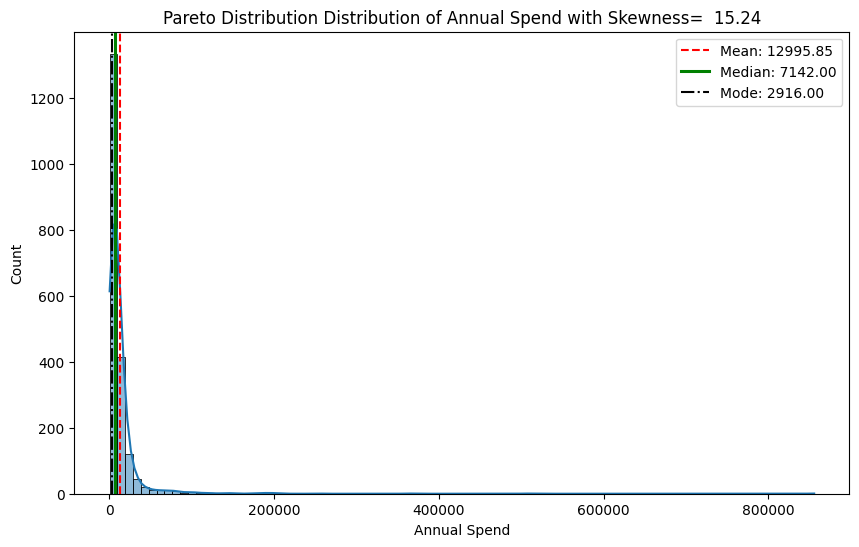

In [ ]:
#annual_spend
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df_imp , x='annual_spend',  kde=True, ax=ax)
ax.axvline(df_imp['annual_spend'].mean(), linestyle='--', color='red',linewidth=1.5, label= f'Mean: {df_imp['annual_spend'].mean():.2f}')
ax.axvline(df_imp['annual_spend'].median(), linestyle='-', color='green',linewidth=2.2, label= f'Median: {df_imp['annual_spend'].median():.2f}')
ax.axvline(df_imp['annual_spend'].mode()[0], linestyle='-.', color='black',linewidth=1.5, label= f'Mode: {df_imp['annual_spend'].mode()[0]:.2f}')

ax.legend()
plt.xlabel('Annual Spend')
plt.title(f'Pareto Distribution Distribution of Annual Spend with Skewness= {df_imp['annual_spend'].skew(): .2f}')
plt.show()

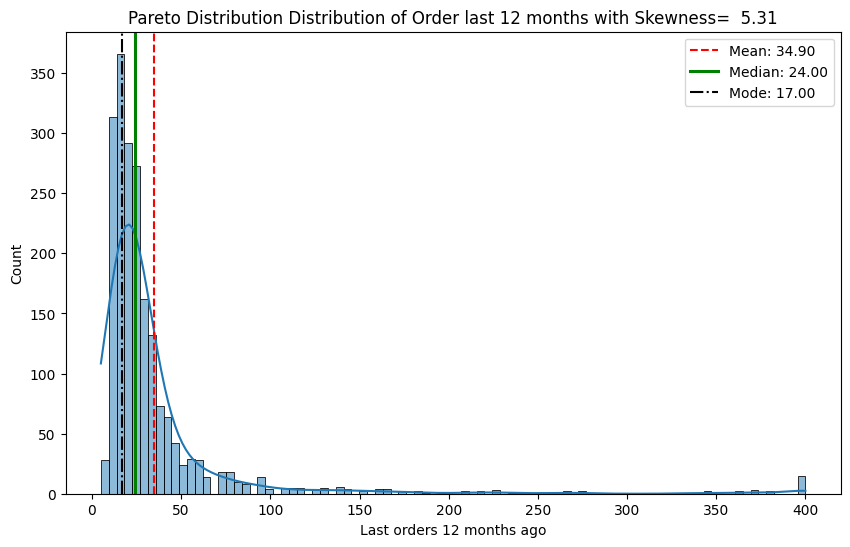

In [ ]:
#orders_last_12m
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df_imp , x='orders_last_12m',  kde=True, ax=ax)
ax.axvline(df_imp['orders_last_12m'].mean(), linestyle='--', color='red',linewidth=1.5, label= f'Mean: {df_imp['orders_last_12m'].mean():.2f}')
ax.axvline(df_imp['orders_last_12m'].median(), linestyle='-', color='green',linewidth=2.2, label= f'Median: {df_imp['orders_last_12m'].median():.2f}')
ax.axvline(df_imp['orders_last_12m'].mode()[0], linestyle='-.', color='black',linewidth=1.5, label= f'Mode: {df_imp['orders_last_12m'].mode()[0]:.2f}')

ax.legend()
plt.xlabel('Last orders 12 months ago')
plt.title(f'Pareto Distribution Distribution of Order last 12 months with Skewness= {df_imp['orders_last_12m'].skew(): .2f}')
plt.show()

Observations: We can see here that the order of mean, median and mode flips according to the Skewness. That is because in case of RIGHT SKEW the data points are mainly concentrated in the left side so Median < Mean(which is affected by the outliers on the right). This nature entirely flips when the distribution is LEFT SKEW and Median > Mean as now the outliers lay in the left.

In [ ]:
#Need to clean the data after outlier treatment and Null Imputaions
df_clean=df_imp.drop(columns=['gender','avg_order_value','customer_rating','discount_used_pct','avg_order_value_global_fill'
,'customer_rating_group','discount_used_pct_mean','gender_mode'], axis=1)


In [ ]:
df_clean.rename({'avg_order_value_group':'avg_order_value','customer_rating_global':'customer_rating',
                 'discount_used_pct_median':'discount_used_pct','gender_clean':'gender'},axis=1, inplace=True)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   device_type             2000 non-null   object        
 5   acquisition_channel     2000 non-null   object        
 6   age                     2000 non-null   float64       
 7   tenure_months           2000 non-null   float64       
 8   app_sessions_per_month  2000 non-null   int64         
 9   delivery_time_min       2000 non-null   float64       
 10  days_since_last_order   2000 non-null   float64       
 11  membership              2000 non-null   object        
 12  orders_last_12m         2000 non-null   int64   

# Task 4: Relationships Between Variables

### Covariance Matrix:

In [ ]:
#Separating numeric columns from categorical columns
df_num=df_clean[df_clean.columns[df_clean.dtypes!='object']]

In [ ]:
df_num.cov() #Covariance matrix

,signup_date,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,days_since_last_order,orders_last_12m,annual_spend,avg_order_value,customer_rating,discount_used_pct
signup_date,6.692872e+32,-3.033202e+14,-2.652273e+15,-2.582212e+17,4.995744e+14,-5.019390e+15,7.768946e+15,1.993024e+16,9.476572e+18,1.310150e+18,-2.814941e+14,4.087509e+14
city_tier,-3.033202e+14,5.961978e-01,5.538544e-02,1.173750e-01,5.236018e-02,1.672140e+00,3.776891e-01,9.481258e-01,-1.021972e+02,-4.851645e+01,-1.903202e-03,-1.559754e-01
age,-2.652273e+15,5.538544e-02,4.733183e+01,1.024655e+00,-4.120600e-01,7.886037e+00,-1.831173e+00,3.266179e+00,5.537221e+03,-2.633592e+02,-1.158604e-02,-1.594563e+01
tenure_months,-2.582212e+17,1.173750e-01,1.024655e+00,9.962639e+01,-1.937505e-01,1.935232e+00,-2.991722e+00,-7.673531e+00,-3.633604e+03,-5.054773e+02,1.084264e-01,-1.580457e-01
app_sessions_per_month,4.995744e+14,5.236018e-02,-4.120600e-01,-1.937505e-01,1.427751e+01,-1.131795e+00,1.871202e+00,1.399696e+01,9.728321e+03,5.270751e+00,2.146673e-02,-9.291216e-01
delivery_time_min,-5.019390e+15,1.672140e+00,7.886037e+00,1.935232e+00,-1.131795e+00,3.647977e+02,-6.911770e+00,-1.420244e+01,-7.620003e+03,-3.214692e+02,3.110611e-01,-3.245825e+00
days_since_last_order,7.768946e+15,3.776891e-01,-1.831173e+00,-2.991722e+00,1.871202e+00,-6.911770e+00,3.603773e+02,8.827962e+00,-9.480868e+03,-1.455110e+02,-7.215585e-01,-6.063885e+00
orders_last_12m,1.993024e+16,9.481258e-01,3.266179e+00,-7.673531e+00,1.399696e+01,-1.420244e+01,8.827962e+00,2.427951e+03,1.083302e+06,-7.360954e+02,-1.854270e-01,5.879196e+00
annual_spend,9.476572e+18,-1.021972e+02,5.537221e+03,-3.633604e+03,9.728321e+03,-7.620003e+03,-9.480868e+03,1.083302e+06,9.202961e+08,1.246466e+06,1.489031e+01,-8.300506e+03
avg_order_value,1.310150e+18,-4.851645e+01,-2.633592e+02,-5.054773e+02,5.270751e+00,-3.214692e+02,-1.455110e+02,-7.360954e+02,1.246466e+06,1.216338e+06,1.087397e+01,-6.095767e+01


### Correlation Matrix

In [ ]:
df_num.corr()

,signup_date,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,days_since_last_order,orders_last_12m,annual_spend,avg_order_value,customer_rating,discount_used_pct
signup_date,1.000000,-0.015184,-0.014902,-0.999996,0.005111,-0.010158,0.015819,0.015635,0.012075,0.045918,-0.019087,0.001711
city_tier,-0.015184,1.000000,0.010426,0.015230,0.017946,0.113384,0.025767,0.024920,-0.004363,-0.056973,-0.004324,-0.021876
age,-0.014902,0.010426,1.000000,0.014922,-0.015851,0.060014,-0.014021,0.009635,0.026531,-0.034709,-0.002954,-0.251002
tenure_months,-0.999996,0.015230,0.014922,1.000000,-0.005137,0.010151,-0.015789,-0.015602,-0.012000,-0.045918,0.019056,-0.001715
app_sessions_per_month,0.005111,0.017946,-0.015851,-0.005137,1.000000,-0.015683,0.026086,0.075177,0.084869,0.001265,0.009966,-0.026629
delivery_time_min,-0.010158,0.113384,0.060014,0.010151,-0.015683,1.000000,-0.019063,-0.015091,-0.013151,-0.015261,0.028569,-0.018404
days_since_last_order,0.015819,0.025767,-0.014021,-0.015789,0.026086,-0.019063,1.000000,0.009438,-0.016463,-0.006950,-0.066676,-0.034593
orders_last_12m,0.015635,0.024920,0.009635,-0.015602,0.075177,-0.015091,0.009438,1.000000,0.724713,-0.013545,-0.006601,0.012921
annual_spend,0.012075,-0.004363,0.026531,-0.012000,0.084869,-0.013151,-0.016463,0.724713,1.000000,0.037255,0.000861,-0.029631
avg_order_value,0.045918,-0.056973,-0.034709,-0.045918,0.001265,-0.015261,-0.006950,-0.013545,0.037255,1.000000,0.017296,-0.005986


Covariance has no range and also has a strict unit of measurement which makes it difficult to judge the strength of a relationship. Whereas Correlation is unitless and have a range of -1 to 1 which helps in determining the strength of relationship between 2 variables more properly.

# Heatmap of the correlation matrix with annotations.

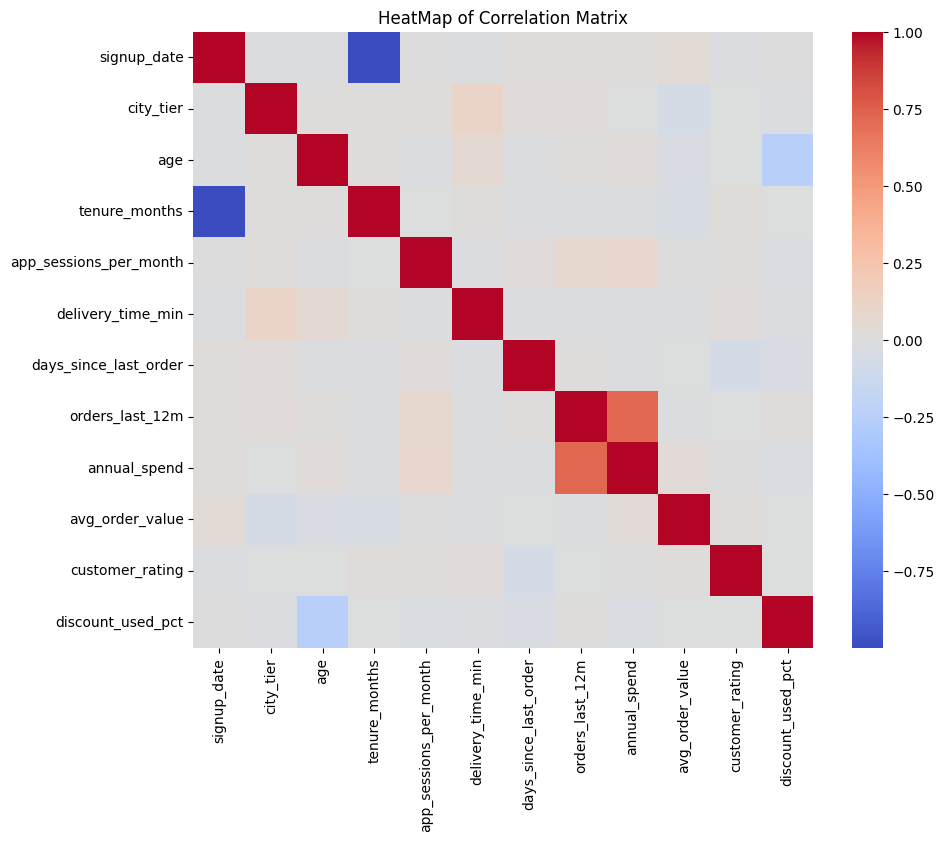

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df_num.corr(), cmap='coolwarm')
plt.title('HeatMap of Correlation Matrix')
plt.xticks(rotation=90)
#plt.yticks(rotation=)
plt.show()

## Scatter plots:

### orders_last_12m vs annual_spend

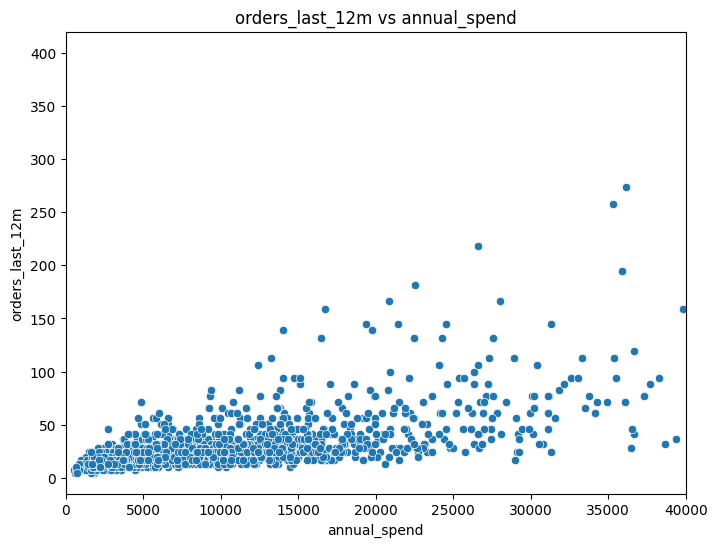

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_clean, y='orders_last_12m', x='annual_spend')
plt.xlim(0,40000)
plt.title('orders_last_12m vs annual_spend')
plt.show()

### app_sessions_per_month vs orders_last_12m

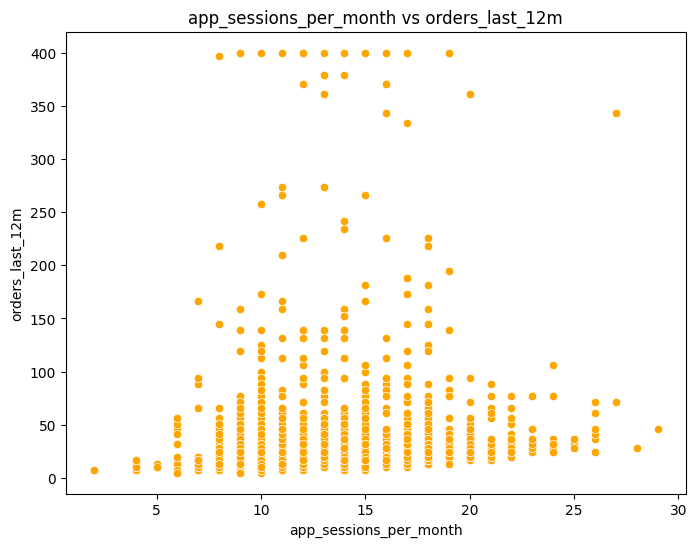

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_clean, x='app_sessions_per_month', y='orders_last_12m', color='orange')
plt.title('app_sessions_per_month vs orders_last_12m')
plt.show()

### delivery_time_min vs customer_rating

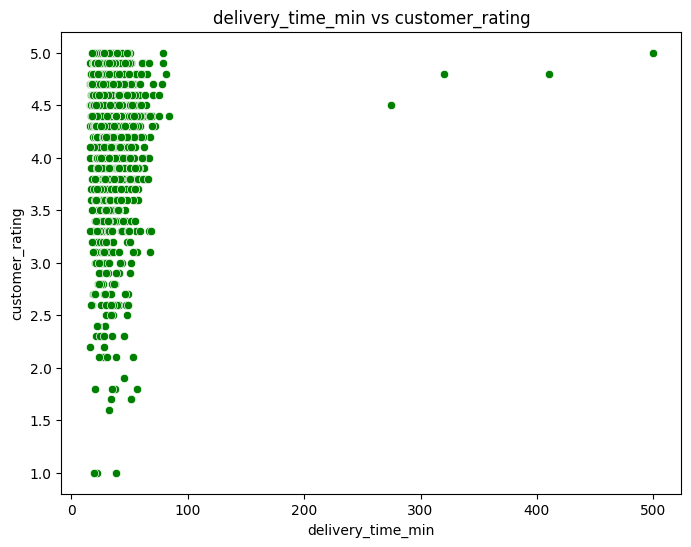

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_clean, x='delivery_time_min', y='customer_rating', color='green')
plt.title('delivery_time_min vs customer_rating')
plt.show()

## Line plot:

### Number of new signups per month

In [ ]:
df_clean['signup_month']=df_clean['signup_date'].dt.month


In [ ]:
df_newsignup=df_clean.groupby('signup_month').agg(count=('signup_date','count'))
df_newsignup

,count
signup_month,
1,172
2,178
3,171
4,165
5,180
6,179
7,188
8,180
9,184


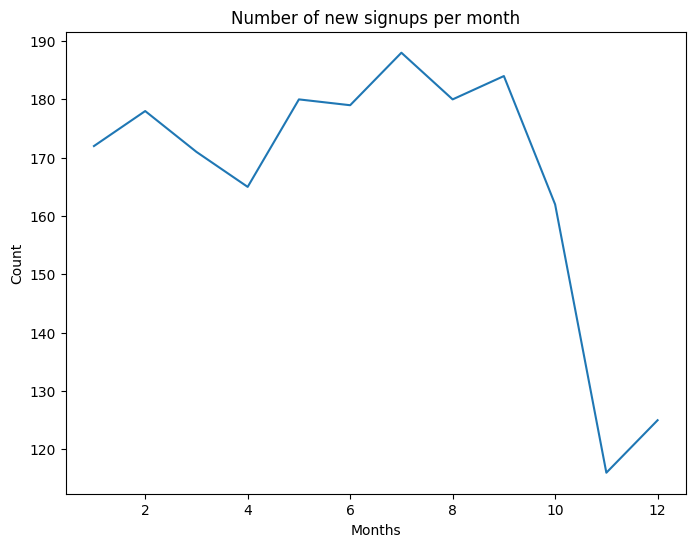

In [ ]:
plt.figure(figsize=(8,6))
sns.lineplot(data=df_newsignup, x='signup_month', y='count')
plt.title('Number of new signups per month')
plt.xlabel('Months')
plt.ylabel('Count')
plt.show()

Insights: Number of new signups has decresed drastically from September to November. The reason to this needs to be investigated.

### Average Minimum Delivery time by signup month and checking relation with new signups

In [ ]:
#df_adt=df_clean.groupby('signup_month')['delivery_time_min'].agg('mean')-> can't plot it as it has no column name
df_adt=df_clean.groupby('signup_month').agg(Average=('delivery_time_min','mean'))
df_adt

,Average
signup_month,
1,35.074128
2,33.576124
3,34.052924
4,36.395152
5,36.085833
6,35.865084
7,35.540160
8,34.369167
9,35.381793


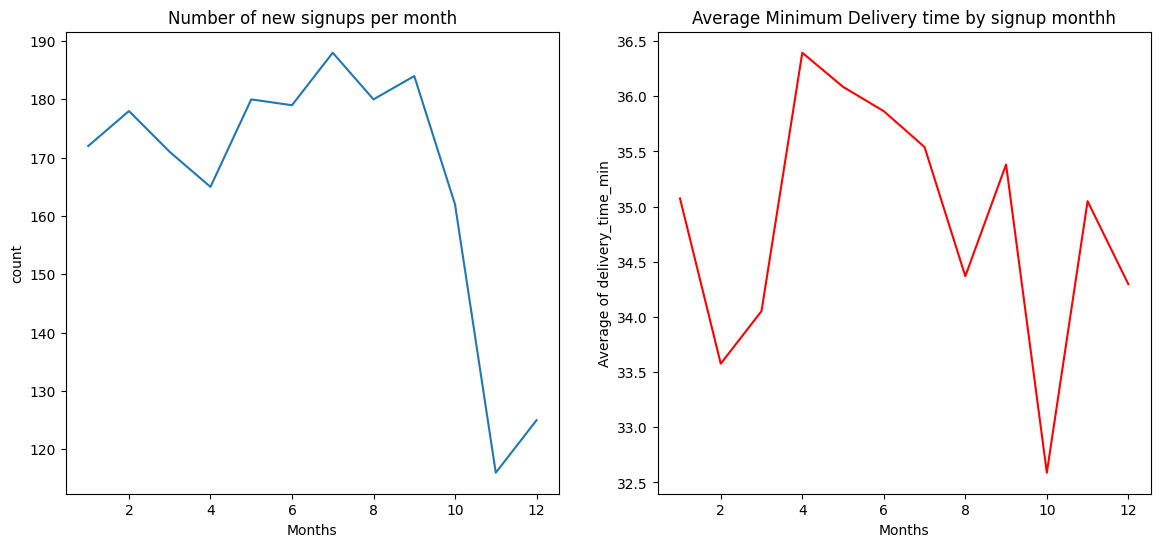

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(14,6))
sns.lineplot(data=df_newsignup, x='signup_month', y='count',ax=ax[0])
ax[0].set_title('Number of new signups per month')
ax[0].set_xlabel('Months')
sns.lineplot(data=df_adt, x='signup_month', y='Average', color='red',ax=ax[1])
ax[1].set_title('Average Minimum Delivery time by signup monthh')
ax[1].set_xlabel('Months')
ax[1].set_ylabel('Average of delivery_time_min')
plt.show()

Insight: If we look at the plots we can see that delivery time was high during september which can lead to decrease in new signups till november. We can see this trend for october and november as well.

## Box plots by category:

### Annual_spend by Membership

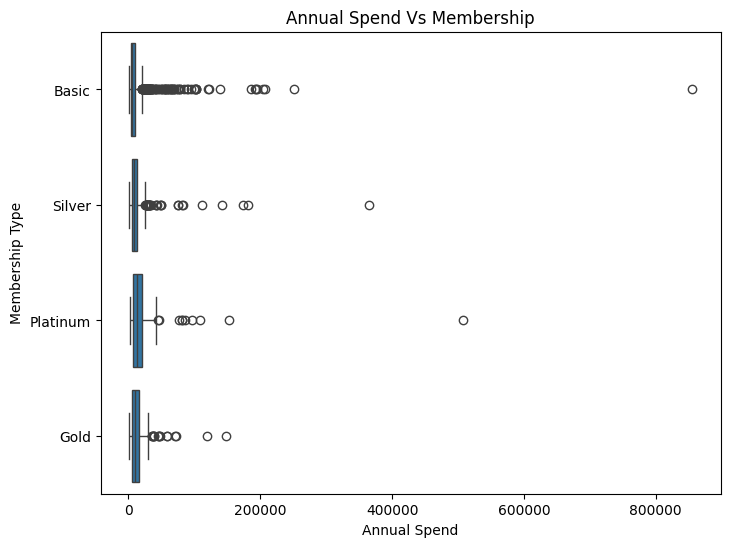

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(y='membership',x='annual_spend', data=df_clean)
plt.title('Annual Spend Vs Membership')
plt.xlabel('Annual Spend')
plt.ylabel('Membership Type')
plt.show()

### delivery_time_min by city_tier

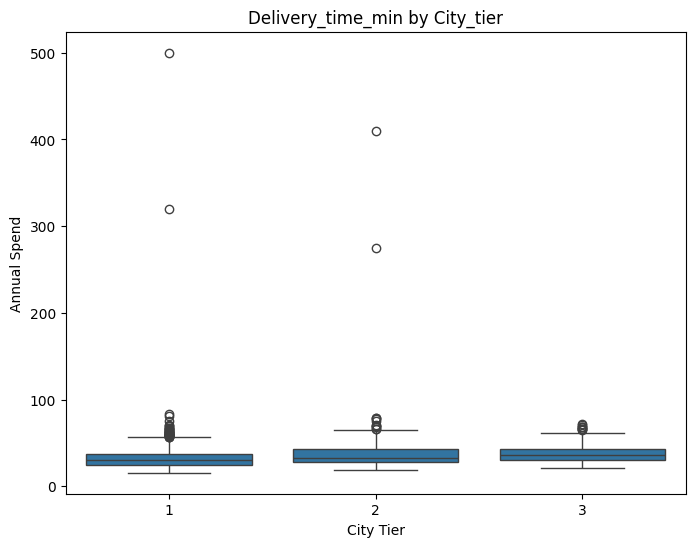

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(y='delivery_time_min', x='city_tier', data=df_clean)
plt.title('Delivery_time_min by City_tier')
plt.xlabel('City Tier')
plt.ylabel('Annual Spend')
plt.show()

Question: Which variable has the strongest relationship with annual_spend

Answer: order_last_12m. Refered from Correlation Matrix.

Question: Does
correlation prove causation?

Answer: No, correlation does not prove causation.
Just because two variables move together  does not mean that one causes the other to happen.

# Task 5: Encoding Categorical Variables

### Label Encoding applied to membership column

In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
mapping={'Basic':0, 'Silver':1, 'Gold':2, 'Platinum':3}
df_clean['membership_encoded']=le.fit_transform(df_clean['membership'].map(mapping))

In [ ]:
df_clean[['membership','membership_encoded']]

,membership,membership_encoded
0,Basic,0
1,Basic,0
2,Basic,0
3,Basic,0
4,Basic,0
...,...,...
1995,Basic,0
1996,Basic,0
1997,Silver,1
1998,Platinum,3


### One Hot encoding applied on device_type and acquisition_channel

In [ ]:
df_enc=pd.get_dummies(df_clean, columns=['device_type','acquisition_channel'],dtype=int)
df_enc

,customer_id,signup_date,city,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,days_since_last_order,membership,...,signup_month,membership_encoded,device_type_Android,device_type_Web,device_type_iOS,acquisition_channel_Influencer,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,QB100000,2023-11-27,Lucknow,2,21.0,35.6,13,45.3,4.0,Basic,...,11,0,1,0,0,0,0,0,1,0
1,QB100001,2025-05-26,Bengaluru,1,43.0,17.4,11,21.9,13.0,Basic,...,5,0,0,0,1,1,0,0,0,0
2,QB100002,2023-02-06,Indore,3,39.0,45.4,12,47.9,1.0,Basic,...,2,0,0,0,1,0,0,0,1,0
3,QB100003,2024-04-09,Jaipur,2,34.0,31.2,13,26.4,7.0,Basic,...,4,0,1,0,0,0,0,1,0,0
4,QB100004,2025-04-12,Mumbai,1,33.0,18.9,17,19.4,12.0,Basic,...,4,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,QB101995,2023-08-07,Jaipur,2,18.0,39.4,9,42.7,6.0,Basic,...,8,0,0,0,1,1,0,0,0,0
1996,QB101996,2025-06-07,Delhi,1,29.0,17.0,7,20.7,6.0,Basic,...,6,0,0,0,1,0,0,0,0,1
1997,QB101997,2025-10-15,Bengaluru,1,45.0,12.7,18,38.0,1.0,Silver,...,10,1,1,0,0,0,0,1,0,0
1998,QB101998,2025-02-22,Indore,3,32.0,20.5,21,68.8,8.0,Platinum,...,2,3,0,0,1,1,0,0,0,0


If looked closely we can see that there is a mathematical redundancy means if android and web =0 then IOS must be 1. This correlation between predictor variables is called dummy variable trap.

To avoid this we can use drop_first=True, which will remove the redundancy and will remove the first alphabetical category column.So now if both Android and Web show 0 it automatically takes IOS as 1.

In [ ]:
#encoding using drop_first=True
df_enc=pd.get_dummies(df_clean, columns=['device_type','acquisition_channel'],drop_first=True,dtype=int)
df_enc


,customer_id,signup_date,city,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,days_since_last_order,membership,...,discount_used_pct,gender,signup_month,membership_encoded,device_type_Web,device_type_iOS,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,QB100000,2023-11-27,Lucknow,2,21.0,35.6,13,45.3,4.0,Basic,...,21.6,Female,11,0,0,0,0,0,1,0
1,QB100001,2025-05-26,Bengaluru,1,43.0,17.4,11,21.9,13.0,Basic,...,0.0,Female,5,0,0,1,0,0,0,0
2,QB100002,2023-02-06,Indore,3,39.0,45.4,12,47.9,1.0,Basic,...,17.8,Male,2,0,0,1,0,0,1,0
3,QB100003,2024-04-09,Jaipur,2,34.0,31.2,13,26.4,7.0,Basic,...,42.9,Female,4,0,0,0,0,1,0,0
4,QB100004,2025-04-12,Mumbai,1,33.0,18.9,17,19.4,12.0,Basic,...,29.2,Male,4,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,QB101995,2023-08-07,Jaipur,2,18.0,39.4,9,42.7,6.0,Basic,...,36.2,Male,8,0,0,1,0,0,0,0
1996,QB101996,2025-06-07,Delhi,1,29.0,17.0,7,20.7,6.0,Basic,...,24.1,Male,6,0,0,1,0,0,0,1
1997,QB101997,2025-10-15,Bengaluru,1,45.0,12.7,18,38.0,1.0,Silver,...,2.9,Male,10,1,0,0,0,1,0,0
1998,QB101998,2025-02-22,Indore,3,32.0,20.5,21,68.8,8.0,Platinum,...,29.4,Male,2,3,0,1,0,0,0,0


### Target Encoding of city by replacing each city with its average annual spend

In [ ]:
df_clean['city_target_encoded']=df_clean['city'].map(df_clean.groupby('city')['annual_spend'].mean())
df_clean[['city','city_target_encoded']]

,city,city_target_encoded
0,Lucknow,13939.898649
1,Bengaluru,12004.006803
2,Indore,10732.646259
3,Jaipur,10410.643357
4,Mumbai,12020.796875
...,...,...
1995,Jaipur,10410.643357
1996,Delhi,12152.446667
1997,Bengaluru,12004.006803
1998,Indore,10732.646259


 Here label encoding will be misleading because label encoding mainly works with ordinal data or nominal data with 2 categories. In city column order of the city doesnt actually matter hence we can't use label encoding.

Here one hot encoding will be wide as there are 10 citites. 10 new columns will be formed in the dataframe and it will cause the curse of dimentionality. It will consume more memory and high computation cost.

When we target encode using the entire dataset,it encounters risk i.e, target leakage, where essentially the value we want to predict leaks into the input data. This gives a non realistic prediction and the whole model falls apart in real world data.

# Task 6: Central Tendency and Percentiles

In [ ]:
df_clean.columns

Index(['customer_id', 'signup_date', 'city', 'city_tier', 'device_type',
       'acquisition_channel', 'age', 'tenure_months', 'app_sessions_per_month',
       'delivery_time_min', 'days_since_last_order', 'membership',
       'orders_last_12m', 'annual_spend', 'avg_order_value', 'customer_rating',
       'discount_used_pct', 'gender', 'signup_month', 'membership_encoded',
       'city_target_encoded'],
      dtype='object')

### Computing mean, median, mode of age , orders_last_12m , annual_spend , and
### membership (mode only for categories).

In [ ]:
#Computing mean, mode and median for age
age_mean=df_clean['age'].mean()
age_median=df_clean['age'].median()
age_mode=df_clean['age'].mode()[0]

print(f'Mean: {age_mean: .2f} and Median: {age_median: .2f} and Mode: {age_mode}',)

Mean:  31.88 and Median:  32.00 and Mode: 32.0


In [ ]:
#Computing Mean, mode and median of last order 12 months
o_mean=df_clean['orders_last_12m'].mean()
o_median=df_clean['orders_last_12m'].median()
o_mode=df_clean['orders_last_12m'].mode()[0]

print(f'Mean: {o_mean:.2f} and Mean: {o_median:.2f} and Mode: {o_mode}')


Mean: 34.90 and Mean: 24.00 and Mode: 17


In [ ]:
#Computing only mode for membership as membership is a categorical column
m_mode=df_clean['membership'].mode()[0]
print(f'Mode: {m_mode}')

Mode: Basic


In [ ]:
#Computing mean, median and mode of annual spend
ans_mean=df_clean['annual_spend'].mean()
ans_median=df_clean['annual_spend'].median()
ans_mode=df_clean['annual_spend'].mode()[0]
print(f'Mean: {ans_mean:.2f} and Median: {ans_median:.2f} and Mode: {ans_mode}')


Mean: 12995.85 and Median: 7142.00 and Mode: 2916.0


In annual spend column Mean>> Median because as shown in the above graph annual spend follows a pareto graph distribution. The column has a heavy right tail hence mean value is highly affected by the outliers making it way graeter than median with doesn't get affected by the long tail.

This actually helps us to infer  that a few percentage of customer contribute to the larger amount of expenditure.

### Computing percentiles from delivery time

In [ ]:
pd10=df_clean['delivery_time_min'].quantile(0.10)
pd25=df_clean['delivery_time_min'].quantile(0.25)
pd75=df_clean['delivery_time_min'].quantile(0.75)
pd90=df_clean['delivery_time_min'].quantile(0.90)
pd95=df_clean['delivery_time_min'].quantile(0.95)
pd99=df_clean['delivery_time_min'].quantile(0.99)

print(f'10th Percentile: {pd10}')
print(f'25th Percentile: {pd25}')
print(f'75th Percentile: {pd75}')
print(f'90th Percentile: {pd90:.2f}')
print(f'95th Percentile: {pd95}')
print(f'99th Percentile: {pd99:.2f}')


10th Percentile: 22.1
25th Percentile: 26.5
75th Percentile: 40.1
90th Percentile: 49.21
95th Percentile: 55.4
99th Percentile: 68.60


### Computing percentiles for Annual Spend

In [ ]:
pa10=df_clean['annual_spend'].quantile(0.10)
pa25=df_clean['annual_spend'].quantile(0.25)
pa75=df_clean['annual_spend'].quantile(0.75)
pa90=df_clean['annual_spend'].quantile(0.90)
pa95=df_clean['annual_spend'].quantile(0.95)
pa99=df_clean['annual_spend'].quantile(0.99)

print(f'10th Percentile: {pa10}')
print(f'25th Percentile: {pa25}')
print(f'75th Percentile: {pa75}')
print(f'90th Percentile: {pa90:.2f}')
print(f'95th Percentile: {pa95:.2f}')
print(f'99th Percentile: {pa99:.2f}')


10th Percentile: 2508.6
25th Percentile: 4085.75
75th Percentile: 12781.25
90th Percentile: 22453.70
95th Percentile: 35355.25
99th Percentile: 109149.78


### Drawing Box Plot for delivery time min

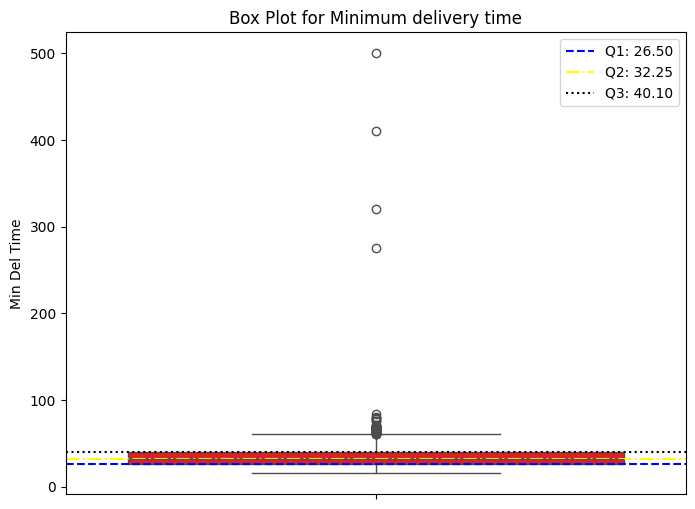

In [ ]:
fig,ax=plt.subplots(figsize=(8,6))
sns.boxplot(y=df_clean['delivery_time_min'], color='red', ax=ax)
ax.axhline(pd25, linestyle='--', color='blue', linewidth=1.5, label=f'Q1: {pd25:.2f}')
ax.axhline(df_clean['delivery_time_min'].median(),linewidth=1.5, linestyle='-.', color='yellow', label=f'Q2: {df_clean['delivery_time_min'].median():.2f}')
ax.axhline(pd75, linestyle=':', color='black',linewidth=1.5, label=f'Q3: {pd75:.2f}')
ax.legend()
plt.title('Box Plot for Minimum delivery time')
plt.ylabel('Min Del Time')
plt.show()

Question: What delivery time do 90% of customers experience or better?"
(P90).

Answer: 49.21%

# Task 7: Pareto Distribution and the 80/20 Rule

In [ ]:
df_sort=df_clean.sort_values(['annual_spend'],ascending=False).reset_index(drop=True)
#Customer Spend share
df_sort['cum_share_spend']=df_sort['annual_spend'].cumsum()
df_sort['rev_share_pct']=(df_sort['annual_spend']/ df_sort['annual_spend'].sum() *100).round(2)
#Cumulative customer pct
df_sort['cum_cust_pct']=((df_sort.index +1)/ len(df_sort)) *100
#Cummunative share pct
run_total=0
cumm=[]
for share in df_sort['rev_share_pct']:
  run_total+=share
  cumm.append(round(run_total,2))
df_sort['cumulative_rev_share_pct']=cumm
df_sort['customer_rank'] = df_sort.index + 1


df_sort.head()

,customer_id,signup_date,city,city_tier,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,...,discount_used_pct,gender,signup_month,membership_encoded,city_target_encoded,cum_share_spend,rev_share_pct,cum_cust_pct,cumulative_rev_share_pct,customer_rank
0,QB100236,2025-09-09,Hyderabad,1,Android,Paid Social,36.0,13.9,15,29.80,...,16.9,Female,9,0,18300.340249,855443.0,3.29,0.05,3.29,1
1,QB100319,2023-02-14,Nagpur,3,Android,Paid Social,31.0,45.2,19,39.00,...,23.8,Unknown,2,3,15515.557692,1362849.0,1.95,0.10,5.24,2
2,QB100687,2023-10-27,Kochi,3,Android,Referral,29.0,36.7,17,32.25,...,6.1,Female,10,1,15739.561905,1727589.0,1.40,0.15,6.64,3
3,QB101686,2025-02-27,Hyderabad,1,Web,Search Ads,23.0,20.4,8,31.40,...,22.5,Male,2,0,18300.340249,1979511.0,0.97,0.20,7.61,4
4,QB101830,2023-12-10,Hyderabad,1,Android,Organic,28.0,35.2,16,34.00,...,31.9,Female,12,0,18300.340249,2186629.0,0.80,0.25,8.41,5


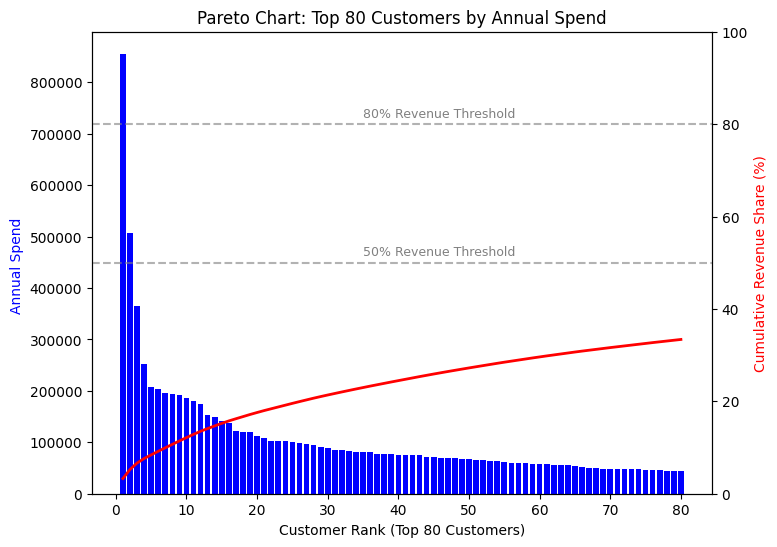

In [ ]:
fig,ax1=plt.subplots(figsize=(8,6))
top_n = 80
df_top = df_sort.head(top_n)

ax1.bar(df_top['customer_rank'], df_top['annual_spend'], color='blue')
ax1.set_xlabel('Customer Rank (Top 80 Customers)')
ax1.set_ylabel('Annual Spend ', color='blue')
ax1.set_title('Pareto Chart: Top 80 Customers by Annual Spend')


ax1_twin = ax1.twinx()
ax1_twin.plot(df_top['customer_rank'], df_top['cumulative_rev_share_pct'], color='red', linewidth=2)
ax1_twin.set_ylabel('Cumulative Revenue Share (%)', color='red')
ax1_twin.set_ylim(0, 100)
ax1_twin.axhline(50, color='gray', linestyle='--', alpha=0.6)
ax1_twin.axhline(80, color='gray', linestyle='--', alpha=0.6)
ax1_twin.text(35, 51.5, '50% Revenue Threshold', color='gray', fontsize=9)
ax1_twin.text(35, 81.5, '80% Revenue Threshold', color='gray', fontsize=9)

plt.show()

In [ ]:
#Extract 50%, 80%, and Top 20% customer benchmarks
cust_50=df_sort[df_sort['cumulative_rev_share_pct']>=50].iloc[0]
cust_80=df_sort[df_sort['cumulative_rev_share_pct']>=80].iloc[0]
top_20_share=df_sort.loc[int(0.20 * len(df_sort)) - 1,'cumulative_rev_share_pct']
print(f'Percentage of customer contributing 50% of revenue: {cust_50['cumulative_rev_share_pct']}')
print(f'Percentage of customer contributing 80% of revenue: {cust_80['cumulative_rev_share_pct']}')
print(f'Top 20% of customers have spend {top_20_share} % of revenue')


Percentage of customer contributing 50% of revenue: 50.07
Percentage of customer contributing 80% of revenue: 80.02
Top 20% of customers have spend 60.65 % of revenue


Insights: According to the classic 80/20 rule, 20% of total population cintributes to 80% of data. As shown above 20% of customers do actually contribute to 60.65% of annual spend.

### Plot annual_spend on a normal scale and a log scale.

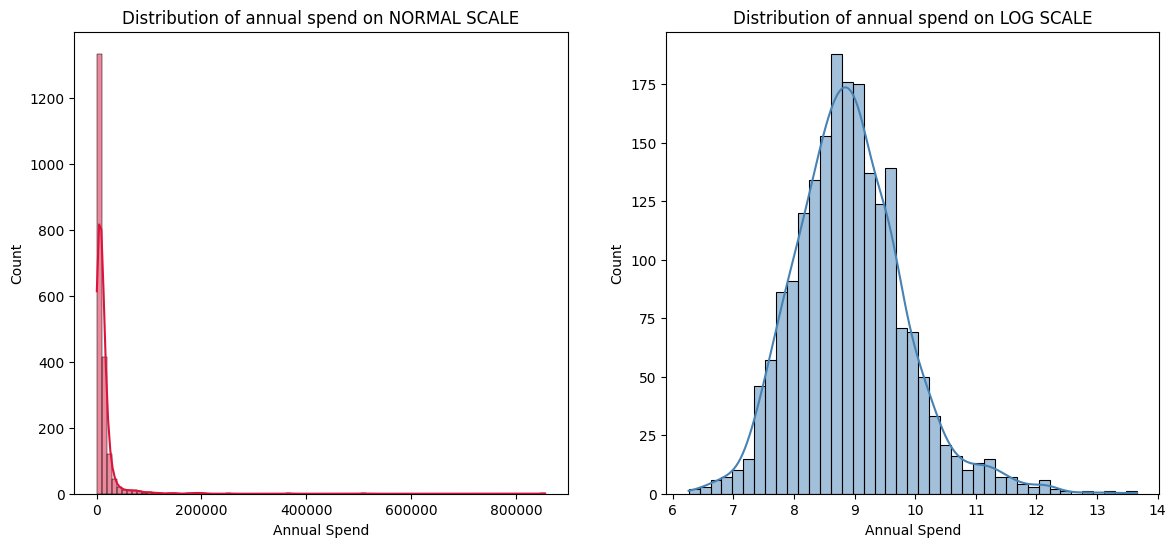

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(14,6))
sns.histplot(x=df_clean['annual_spend'], color='crimson', kde=True, ax=ax[0])
ax[0].set_title('Distribution of annual spend on NORMAL SCALE')
ax[0].set_xlabel('Annual Spend')
sns.histplot(x=np.log(df_clean['annual_spend']), color='steelblue', kde=True, ax=ax[1])
ax[1].set_title('Distribution of annual spend on LOG SCALE')
ax[1].set_xlabel('Annual Spend')
plt.show()

Insights: As seen in the plots above, the distribution in normal scale is giving us a Right Skewed plot with a heavy long tail. This actually gives us the idea that the main data is clustered at the left side of the graph. Rest are outliers.

Whereas when the scale changes to logarithmic scale the same data adjust itself as an approx. normal distribution as infered from the bell-shaped curve.The log scale mathematically compresses the long right tail while expanding the clustered values on the left.

# Task 8: PDF and CDF

### Plotting the PDF (KDE or normalised histogram) of delivery_time_min .

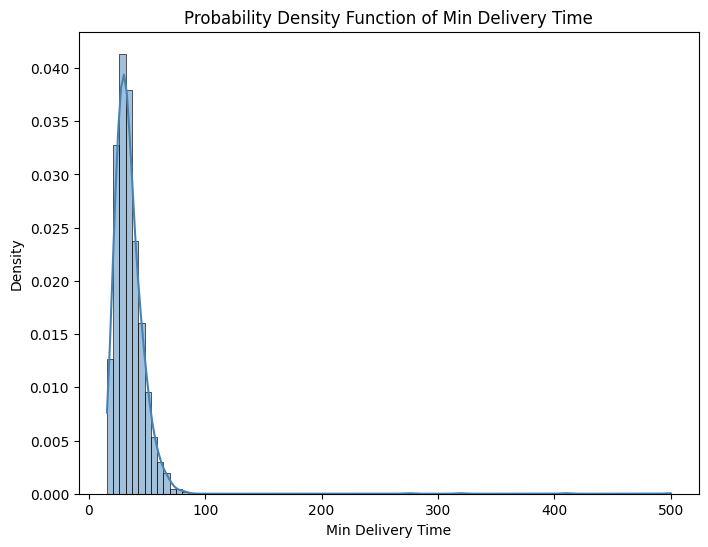

In [ ]:
plt.figure(figsize=(8,6))
sns.histplot(x=df_clean['delivery_time_min'], kde=True, color='steelblue', stat='density')
plt.title('Probability Density Function of Min Delivery Time')
plt.xlabel('Min Delivery Time')
plt.ylabel('Density')
plt.show()

### Plotting the empirical CDF

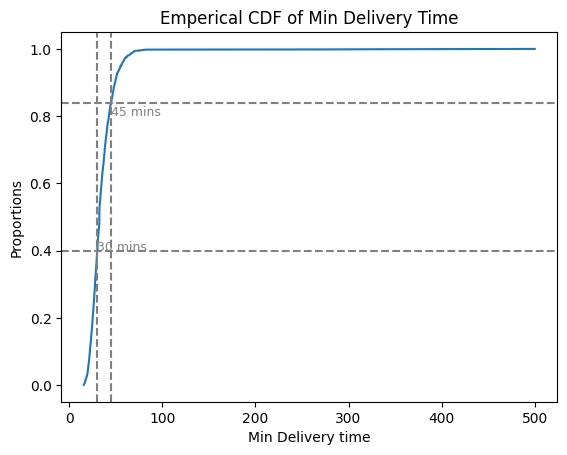

In [ ]:
n=len(df_clean)
x=np.sort(df_clean['delivery_time_min']) #-> data points sorted
y=np.arange(1, n+1)/n #-> proportions

plt.plot(x,y)
plt.title('Emperical CDF of Min Delivery Time')
plt.xlabel('Min Delivery time')
plt.ylabel('Proportions')
plt.axvline(30, linestyle='--', color='gray')
plt.axhline(0.4, linestyle='--', color='gray')
plt.text(30, 0.4, '30 mins', color='gray', fontsize=9)
plt.axvline(45, linestyle='--', color='gray')
plt.axhline(0.84, linestyle='--', color='gray')
plt.text(45, 0.8, '45 mins', color='gray', fontsize=9)
plt.show()

Question: What is the probability a delivery takes ≤ 30 minutes?

Answer:According to the chart above the probablity is 0.4

Question: What is the probability a delivery takes > 45 minutes?

Answer: According to the chart the probability is 16%

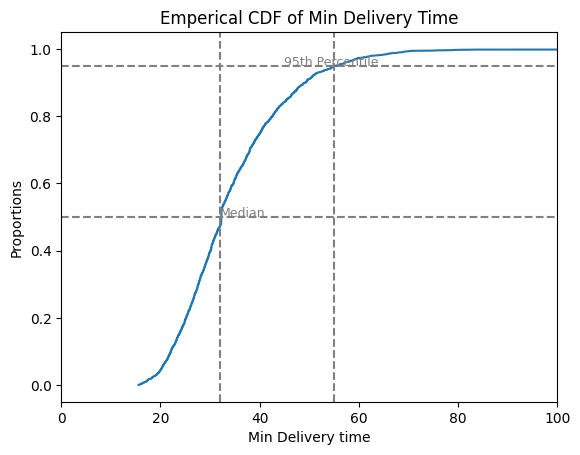

In [ ]:
n=len(df_clean)
x=np.sort(df_clean['delivery_time_min']) #-> data points sorted
y=np.arange(1, n+1)/n #-> proportions

plt.plot(x,y)
plt.title('Emperical CDF of Min Delivery Time')
plt.xlabel('Min Delivery time')
plt.xlim(0,100)
plt.ylabel('Proportions')
plt.axvline(32, linestyle='--', color='gray')
plt.axhline(0.5, linestyle='--', color='gray')
plt.text(32, 0.5, 'Median', color='gray', fontsize=9)
plt.axvline(55, linestyle='--', color='gray')
plt.axhline(0.95, linestyle='--', color='gray')
plt.text(45, 0.95, '95th Percentile', color='gray', fontsize=9)
plt.show()

Question: What time corresponds to the median and the 95th percentile?

Answer: Median: time corresponds to 32 min and 95th Percentile: time corresponds to 55 mins

### Plotting CDF for age

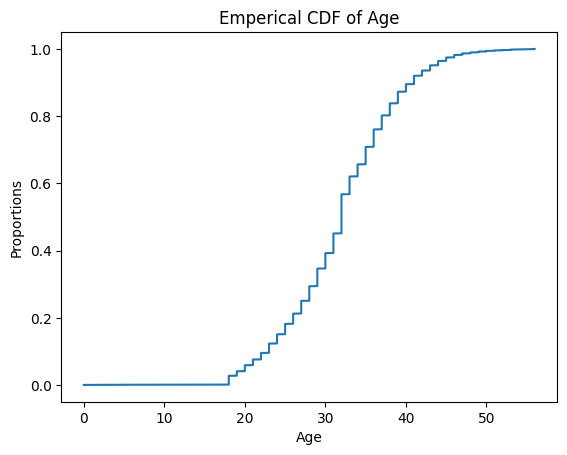

In [ ]:
n=len(df_clean)
x=np.sort(df_clean['age']) #-> data points sorted
y=np.arange(1, n+1)/n #-> proportions

plt.plot(x,y)
plt.title('Emperical CDF of Age')
plt.xlabel('Age')
plt.ylabel('Proportions')
plt.show()

Insights: According to the CDF of delivery time and age ,we can infer tha in case of delivery time there is a steep vertical jump. This means that a lot of data are clustered tightly around x-value.

Whereas we can see vertical steps for age which means it has duplicate exact values on the dataset and almost all the data points fall under the range of 20 to 50 approximately.

PDF or probability Desity Function actually tells us how dense values are around a point. It is applicable on Continuous random variable hence it deals with relative likelihood of density around a point rather than absolute probability which is the case for discrete variables.

Now CDF or cumulative density function tells us how much share of data are actually less that or equal to a datapoint.

# Final Cleaning of the dataset before saving it

In [ ]:
df_clean.head()

,customer_id,signup_date,city,city_tier,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,...,membership,orders_last_12m,annual_spend,avg_order_value,customer_rating,discount_used_pct,gender,signup_month,membership_encoded,city_target_encoded
0,QB100000,2023-11-27,Lucknow,2,Android,Referral,21.0,35.6,13,45.3,...,Basic,17,8675.0,572.0,4.4,21.6,Female,11,0,13939.898649
1,QB100001,2025-05-26,Bengaluru,1,iOS,Influencer,43.0,17.4,11,21.9,...,Basic,24,7896.0,329.0,4.9,0.0,Female,5,0,12004.006803
2,QB100002,2023-02-06,Indore,3,iOS,Referral,39.0,45.4,12,47.9,...,Basic,17,1826.0,118.0,3.8,17.8,Male,2,0,10732.646259
3,QB100003,2024-04-09,Jaipur,2,Android,Paid Social,34.0,31.2,13,26.4,...,Basic,379,90202.0,303.0,4.4,42.9,Female,4,0,10410.643357
4,QB100004,2025-04-12,Mumbai,1,Android,Search Ads,33.0,18.9,17,19.4,...,Basic,17,2773.0,191.0,4.0,29.2,Male,4,0,12020.796875


In [ ]:
quickbites_clean=df_clean.copy()

In [ ]:
quickbites_clean.drop(['membership_encoded','city_target_encoded'],axis=1, inplace=True)

In [ ]:
quickbites_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   device_type             2000 non-null   object        
 5   acquisition_channel     2000 non-null   object        
 6   age                     2000 non-null   float64       
 7   tenure_months           2000 non-null   float64       
 8   app_sessions_per_month  2000 non-null   int64         
 9   delivery_time_min       2000 non-null   float64       
 10  days_since_last_order   2000 non-null   float64       
 11  membership              2000 non-null   object        
 12  orders_last_12m         2000 non-null   int64   

In [ ]:
#checking if there are any duplicate records
quickbites_clean.duplicated().sum()

np.int64(0)

In [ ]:
#Exporting clean dataset
quickbites_clean.to_csv('quickbites_clean.csv', sep=',', index=False)